This notebook is intended to illustrate what hyperparameter and network architecture tuning can look like. There is no single way to do this, you could try to get a good intuition for what works, or you could just brute force as many combinations as possible. We will try the manual approach here. You can use the methods/insights from this notebook in your own assignment, but make sure to write the code yourself, have a good understanding of whats going on, and double check that it works in your context.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from sklearn.model_selection import train_test_split
from torch import nn, optim
from utils import plot_complex_fit

torch.manual_seed(0)
np.random.seed(0)

ModuleNotFoundError: No module named 'utils'

In [ ]:
data = pd.read_csv("regression_data.csv")
train = data[data["split"] == "train"]
test = data[data["split"] == "test"]

As always, we start by understanding the data we are working with.

In [ ]:
train.head()

,x0,x1,y,split
0,0.547847,-1.674705,-4.361448,train
1,-0.920853,1.500913,6.339047,train
2,-1.836106,1.766825,13.208934,train
3,-1.933889,-0.952544,-1.236744,train
4,1.253081,-1.951594,-13.754631,train


In [ ]:
train.shape, test.shape

((400, 4), (100, 4))

We have 4 columns, 2 are input features, 1 is the target, 1 is the split

In [ ]:
train.describe()

,x0,x1,y
count,400.000000,400.000000,400.000000
mean,0.122748,0.003092,0.130722
std,1.180827,1.130634,4.781687
min,-1.998797,-1.999240,-15.364323
25%,-0.854925,-0.991732,-1.939314
50%,0.221852,-0.064954,0.275004
75%,1.189114,1.021293,2.437497
max,1.988840,1.998005,15.641089


In [ ]:
test.describe()

,x0,x1,y
count,100.000000,100.000000,0.0
mean,0.124206,0.048688,NaN
std,1.044973,1.092127,NaN
min,-1.980402,-1.999113,NaN
25%,-0.728037,-0.817697,NaN
50%,0.258373,0.216833,NaN
75%,0.851375,0.877810,NaN
max,1.962979,1.867514,NaN


we have 400 rows to train with (y is given). we have 100 rows we will be tested on, these are evaluated with the given 'plot_complex_fit' function.

we can see that the input features (x0, x1) have near identical distributions in train and test (the statistics match), so nothing shady going on there.

In [ ]:
train_features = train[["x0", "x1"]].values
test_features = test[["x0", "x1"]].values

Mean y value: 0.13072227738835177
RMSE on train: 4.77570567211684


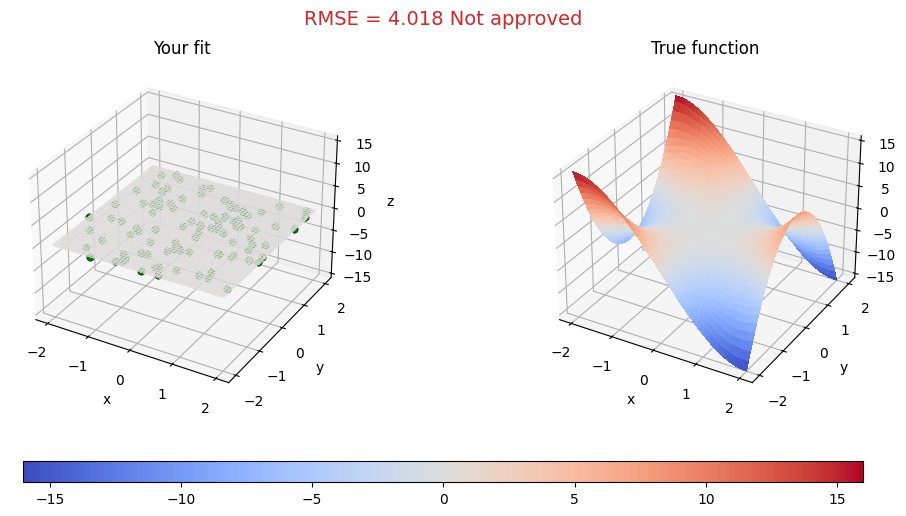

In [ ]:
# Lets try to always predict the mean y value, thats a simple baseline to beat.
mean_y = train["y"].mean()
print(f"Mean y value: {mean_y}")

all_mean_train = np.ones(train_features.shape[0]) * mean_y
all_mean_test = np.ones(test_features.shape[0]) * mean_y

# RMSE on train. we have y values, so we can calculate this.
rmse_train = np.sqrt(np.mean((train["y"] - all_mean_train) ** 2))
print(f"RMSE on train: {rmse_train}")

# These are hidden, so we have to evaluate via the plot_complex_fit function.
plot_complex_fit(test_features, all_mean_test)
plt.show()

Hmm, there is a significant gap between train and test RMSE (4.77 vs 4.018). Only predicting the mean should've given similar RMSE... If we look in utils.py we can see that the underlying function that we want to estimate is the polynomial:

In [ ]:
def complex_function(x, y):
    return x**3 - 3 * x * y**2

We obviously can't modify or use this function to solve the assignment, but lets see what happens if we were to predict perfect y values

RMSE on train (perfect): 1.0298929888576531


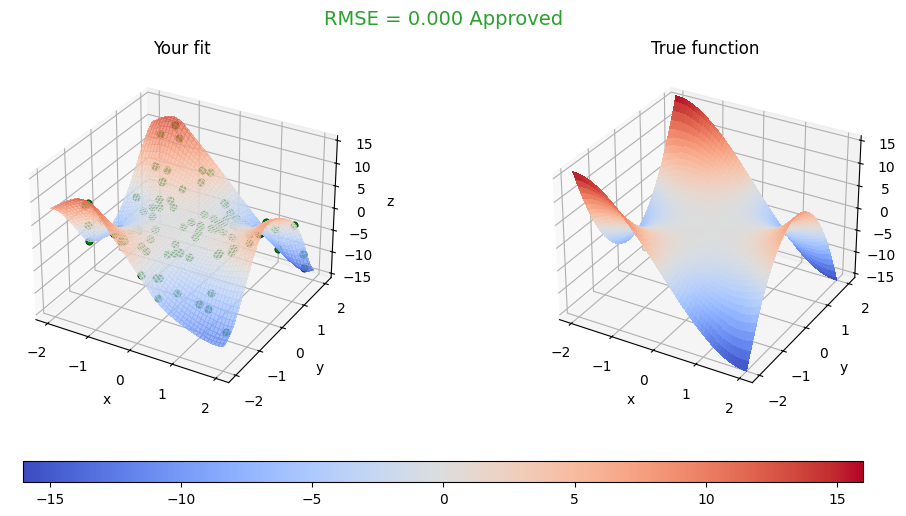

In [ ]:
perfect_y_train = complex_function(train_features[:, 0], train_features[:, 1])
perfect_y_test = complex_function(test_features[:, 0], test_features[:, 1])

rmse_train_perfect = np.sqrt(np.mean((train["y"] - perfect_y_train) ** 2))
print(f"RMSE on train (perfect): {rmse_train_perfect}")

plot_complex_fit(test_features, perfect_y_test)
plt.show()

With perfect training predictions the ceiling is 1.03. That means the training data must be noisy. Noise is not predictable, so anything below 1.03 here would be overfitting to the training data. If we split our training data to create a validation set, then we expect a similar ceiling.

We also notice that the test set gets an RMSE of exactly 0. This means that our model is evaluated on the ground truth function that we are estimating, not some noisy sampled version of it. This actually makes it easier to score well on the test set compared to train/val.

In the spirit of real machine learning applications, lets pretend that we know very little about the test set. If we minimize some validation loss, then we can expect that the test loss will also be minimized (they correlate, but the scale is different).

In [ ]:
# Lets create a validation split
train, val = train_test_split(train, test_size=0.2, random_state=0)

train_features = train[["x0", "x1"]].values
train_y = train["y"].values

val_features = val[["x0", "x1"]].values
val_y = val["y"].values

print(f"Train shape: {train_features.shape}, Validation shape: {val_features.shape}")

Train shape: (320, 2), Validation shape: (80, 2)


We made an 80-20 split, so 80% of the training data is used for training, and 20% is used for validation. If we later find that we need as much training data as possible, we could try k-fold cross validation (at the cost of compute time)

Lets start with a simple neural network with a single hidden layer

In [ ]:
# Convert the data to tensors (the object that pytorch uses to handle data)
# The numpy arrays above stay as they are, so those cells can still be rerun.
X_train = torch.tensor(train_features, dtype=torch.float32)
y_train = torch.tensor(train_y, dtype=torch.float32).unsqueeze(-1)
X_val = torch.tensor(val_features, dtype=torch.float32)
y_val = torch.tensor(val_y, dtype=torch.float32).unsqueeze(-1)
X_test = torch.tensor(test_features, dtype=torch.float32)

print(f"Train features shape: {X_train.shape}")
print(f"Train y shape: {y_train.shape}")
print(f"Val features shape: {X_val.shape}")
print(f"Val y shape: {y_val.shape}")
print(f"Test features shape: {X_test.shape}")

Train features shape: torch.Size([320, 2])
Train y shape: torch.Size([320, 1])
Val features shape: torch.Size([80, 2])
Val y shape: torch.Size([80, 1])
Test features shape: torch.Size([100, 2])


Epoch 0, Loss: 23.020748138427734
Epoch 10, Loss: 21.935327529907227
Epoch 20, Loss: 21.18000030517578
Epoch 30, Loss: 20.563112258911133
Epoch 40, Loss: 20.10097312927246
Epoch 50, Loss: 19.72382354736328
Epoch 60, Loss: 19.402122497558594
Epoch 70, Loss: 19.125064849853516
Epoch 80, Loss: 18.882022857666016
Epoch 90, Loss: 18.663599014282227


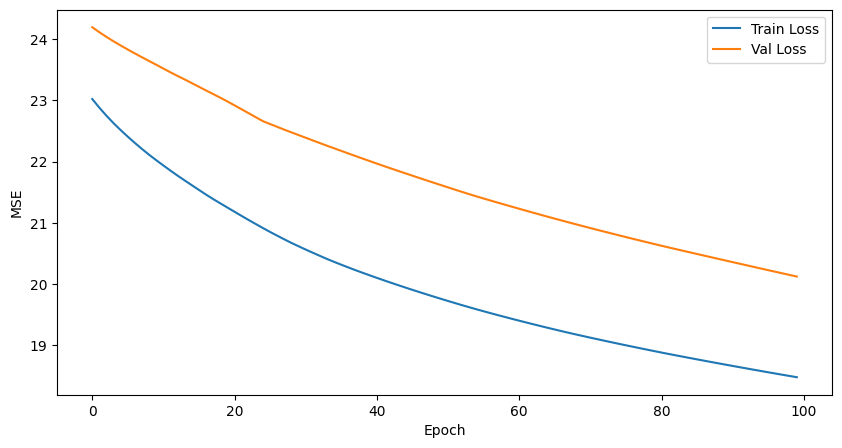

In [ ]:
# There are many ways to write this in pytorch. Personally I think classes are nice, but they are a bit overkill here.
# This architecture and hyperparameters were just randomly chosen, as a starting point.
class SimpleNN(nn.Module):
    def __init__(self):
        super(SimpleNN, self).__init__()
        self.fc1 = nn.Linear(2, 10)
        self.fc2 = nn.Linear(10, 1)

    def forward(self, x):
        x = torch.relu(self.fc1(x))
        x = self.fc2(x)
        return x

# Initialize the model
model = SimpleNN()

# Define the loss function and optimizer
criterion = nn.MSELoss()
optimizer = optim.SGD(model.parameters(), lr=0.01)

# Training loop
# Pytorch does not do all the training steps for us, so we have to do some manually.
# We also have to manually zero the gradients, otherwise pytorch would just accumulate them (we want to start with a fresh gradient for each SGD step)
# We then forward pass the training data, calculate the loss, and then backpropagate the loss.
# After backward, the optimizer has access to the gradient, and a simple step function will update the parameters.
train_losses = []
val_losses = []
for epoch in range(100):
    optimizer.zero_grad()
    outputs = model(X_train)
    loss = criterion(outputs, y_train)
    loss.backward()
    optimizer.step()

    # We also evaluate the model on the validation set, to see how it performs on unseen data.
    with torch.no_grad():
        val_outputs = model(X_val)
        val_loss = criterion(val_outputs, y_val)
    val_losses.append(val_loss.item())
    train_losses.append(loss.item())
    if epoch % 10 == 0:
        print(f"Epoch {epoch}, Loss: {loss.item()}")

# After training, we can evaluate the model on the validation set.
model.eval()
with torch.no_grad():
    val_outputs = model(X_val)

# Plot the loss curves
plt.figure(figsize=(10, 5))
plt.plot(train_losses, label='Train Loss')
plt.plot(val_losses, label='Val Loss')
plt.xlabel('Epoch')
plt.ylabel('MSE')
plt.legend()
plt.show()

Recall that the assignment grades us on RMSE and not MSE. But RMSE = sqrt(MSE), so decreasing MSE strictly decrease RMSE. 

Right now our model get about MSE = 20, so RMSE = sqrt(20) = 4.47. Our simple MLP is not doing great. Because there is no plateau or signs of overfitting, we should probably train the model longer.

Instead of copy pasting the same code for each cell, lets make a generic 'run_experiment' function. This is just for demonstration purposes, in your assignment, its probably easier to change and rerun your cells directly.

In [ ]:
def create_mlp(neurons_per_layer, activation_function):
    # Includes the input and output sizes. [2, 10, 1] means input 2, one hidden layer of 10, output 1.
    # activation_function is a module instance, e.g. nn.ReLU(). It is used on every layer except the output.
    model = nn.Sequential()
    for i in range(1, len(neurons_per_layer)):
        model.add_module(f"fc{i}", nn.Linear(neurons_per_layer[i-1], neurons_per_layer[i]))
        if i < len(neurons_per_layer) - 1: # No activation function in the output layer ==> outputs are not constrained (-inf to inf)
            model.add_module(f"activation{i+1}", type(activation_function)())
    return model

def run_experiment(neurons_per_layer, activation_function, learning_rate, num_epochs, optimizer=optim.SGD, momentum=0.0, patience=None, verbose=True, plot_losses=True):
    model = create_mlp(neurons_per_layer, activation_function)
    criterion = nn.MSELoss()
    if optimizer == optim.SGD:
        optimizer = optimizer(model.parameters(), lr=learning_rate, momentum=momentum)
    else:
        optimizer = optimizer(model.parameters(), lr=learning_rate)

    train_losses = []
    val_losses = []
    best_val = float("inf")
    best_state = None
    stale = 0
    min_delta = 0.001
    for epoch in range(num_epochs):
        optimizer.zero_grad()
        # Notice that this is not 'true' SGD right now. But full-batch gradient descent.
        # If we want standard SGD, we would have to sample batches.
        # Lets not worry about that for now.
        outputs = model(X_train)
        loss = criterion(outputs, y_train)
        loss.backward()
        optimizer.step()

        with torch.no_grad():
            val_outputs = model(X_val)
            val_loss = criterion(val_outputs, y_val)
        val_losses.append(val_loss.item())
        train_losses.append(loss.item())

        if patience is not None:
            # Keep the weights from the best validation epoch, and stop if it has not improved for 'patience' epochs.
            if val_loss.item() < best_val - min_delta:
                best_val = val_loss.item()
                best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
                stale = 0
            else:
                stale += 1
                if stale >= patience:
                    break

        # every 10th percentile of the training loss
        if verbose and (epoch % (num_epochs // 10) == 0):
            print(f"Epoch {epoch}, train loss: {loss.item()}, val loss: {val_loss.item()}")
    if verbose:
        print(f"Epoch {epoch}, train loss: {loss.item()}, val loss: {val_loss.item()}")

    if best_state is not None:
        model.load_state_dict(best_state)

    # After training, we can evaluate the model on the validation and test set.
    model.eval()
    with torch.no_grad(): # no gradients needed under evaluation (this is slightly faster and good practice)
        outputs = model(X_train)
        val_outputs = model(X_val)
        test_outputs = model(X_test)

    train_rmse = np.sqrt(criterion(outputs, y_train).item())
    val_rmse = np.sqrt(criterion(val_outputs, y_val).item())
    if verbose:
        print(f"Train RMSE: {train_rmse}, Val RMSE: {val_rmse}")
    if plot_losses:
        # plot the loss curves
        plt.figure(figsize=(10, 5))
        plt.plot(train_losses, label='Train Loss')
        plt.plot(val_losses, label='Validation Loss')
        plt.xlabel('Epoch')
        plt.ylabel('Loss')
        plt.legend()
        plt.show()

    return model, train_rmse, val_rmse

# For testing architectures later on
def sweep(layers, repeats, activation_function, learning_rate, num_epochs, **kwargs):
    means, stds = [], []
    for layer in layers:
        scores = [
            run_experiment(layer, activation_function, learning_rate, num_epochs, verbose=False, plot_losses=False, **kwargs)[2]
            for _ in range(repeats)
        ]
        means.append(np.mean(scores))
        stds.append(np.std(scores))
    return means, stds

We have tons of things to test now. If these are not enough, we could try e.g weight initialization, regularization, batch normalization, learning rate decay, feature engineering etc.

Epoch 0, train loss: 23.150806427001953, val loss: 24.216856002807617
Epoch 500, train loss: 8.483532905578613, val loss: 10.016180038452148
Epoch 1000, train loss: 5.668405055999756, val loss: 6.888329982757568
Epoch 1500, train loss: 4.120302200317383, val loss: 5.835753917694092
Epoch 2000, train loss: 3.5512280464172363, val loss: 5.2446818351745605
Epoch 2500, train loss: 3.9941132068634033, val loss: 6.328912258148193
Epoch 3000, train loss: 3.9784038066864014, val loss: 6.258831977844238
Epoch 3500, train loss: 3.994368314743042, val loss: 6.293330192565918
Epoch 4000, train loss: 3.9969170093536377, val loss: 6.297287940979004
Epoch 4500, train loss: 3.964897871017456, val loss: 6.265036582946777
Epoch 4999, train loss: 3.925135850906372, val loss: 5.0630598068237305
Train RMSE: 1.9836771781838178, Val RMSE: 2.250124398077522


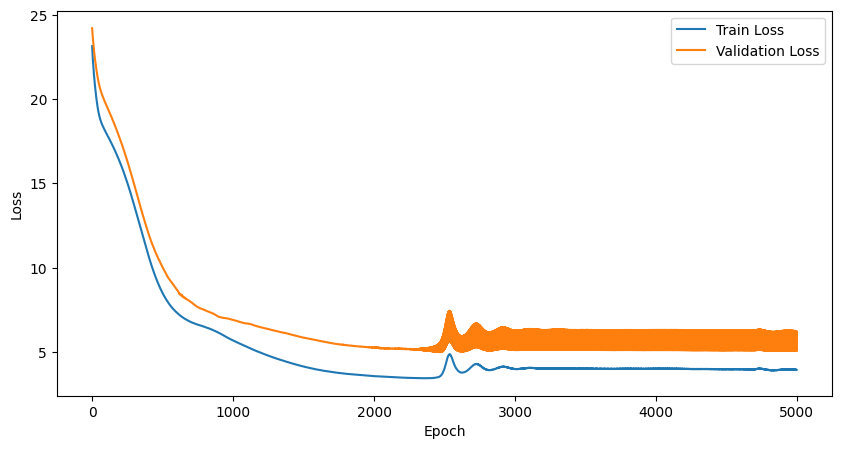

In [ ]:
# Lets train longer this time. It's much easier to compare models when they are trained to completion.
_ = run_experiment(neurons_per_layer=[2, 10, 1], activation_function=nn.ReLU(), learning_rate=0.01, num_epochs=5000)

The loss falls smoothly for about 2000 epochs, and the validation loss follows the training loss. After that it stops improving and starts oscillating. We should probably have stopped training there. A learning rate scheduler, which starts higher and decreases over epochs, would also be reasonable.

Lets use early stopping so we can stop the training before it gets too bad. This will also save us some compute.

Epoch 0, train loss: 22.195331573486328, val loss: 23.26247215270996
Epoch 500, train loss: 8.684185981750488, val loss: 8.606550216674805
Epoch 1000, train loss: 3.33097767829895, val loss: 3.4460372924804688
Epoch 1500, train loss: 2.6302413940429688, val loss: 2.7497498989105225
Epoch 1994, train loss: 2.249422550201416, val loss: 2.3600850105285645
Train RMSE: 1.5014151414537866, Val RMSE: 1.5361020035997794


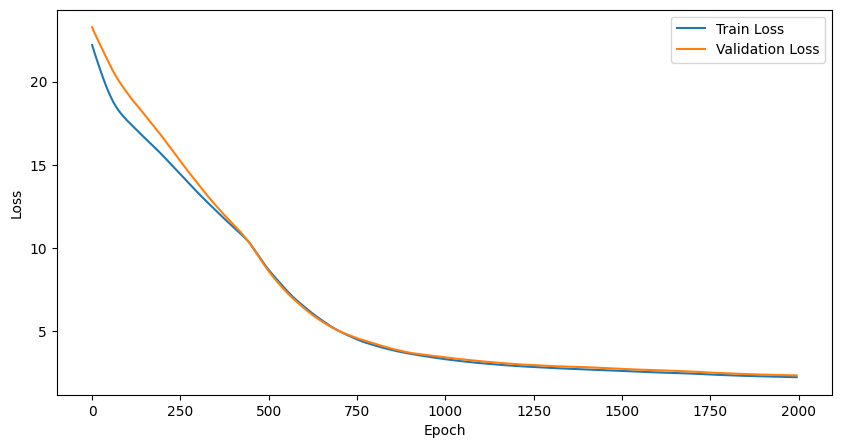

In [ ]:
_ = run_experiment(neurons_per_layer=[2, 10, 1], activation_function=nn.ReLU(), learning_rate=0.01, num_epochs=5000, patience=10)

Much better! Now we don't have to worry about the exact epoch amount any more either. The loop keeps the weights from the best validation epoch. Otherwise we would return the model from 10 epochs after it started getting worse. The printed RMSE is that restored model.

Lets see what happens if we increase or decrease the learning rate

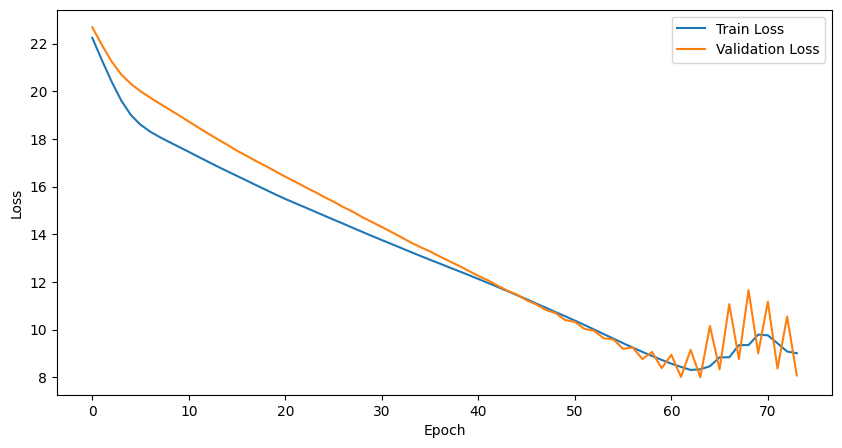

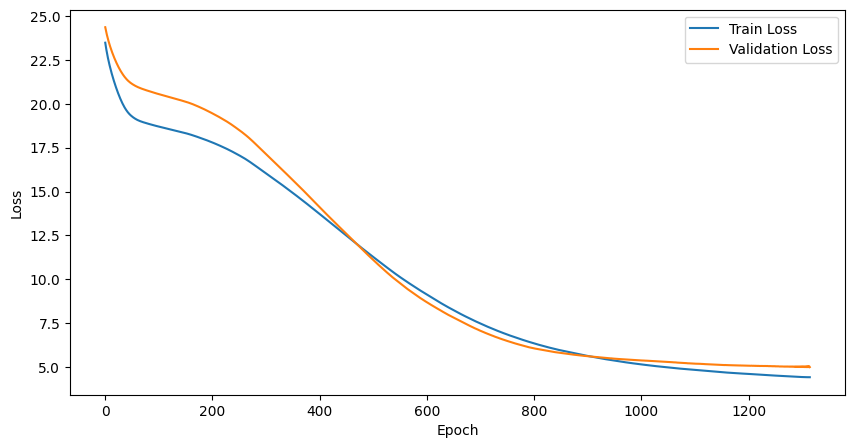

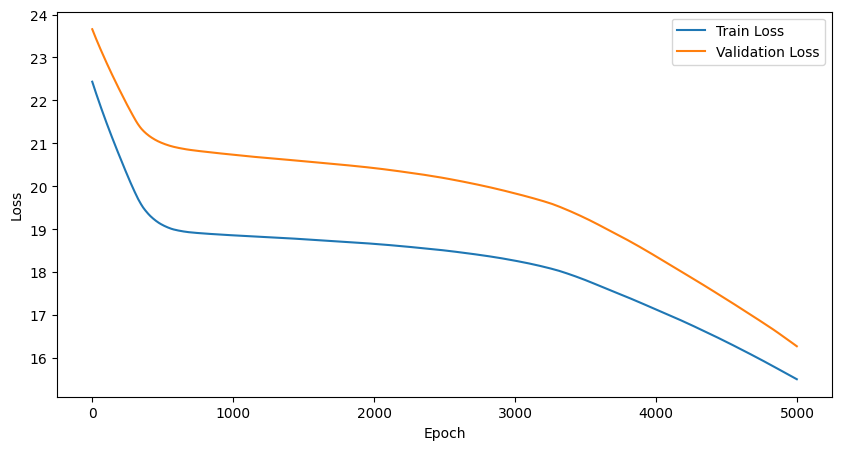

In [ ]:
_ = run_experiment(neurons_per_layer=[2, 10, 1], activation_function=nn.ReLU(), learning_rate=0.1, num_epochs=5000, patience=10, verbose=False)
_ = run_experiment(neurons_per_layer=[2, 10, 1], activation_function=nn.ReLU(), learning_rate=0.01, num_epochs=5000, patience=10, verbose=False)
_ = run_experiment(neurons_per_layer=[2, 10, 1], activation_function=nn.ReLU(), learning_rate=0.001, num_epochs=5000, patience=10, verbose=False)

It seems like the original learning rate is the better of the three. When we increase it the learning becomes unstable very fast. When we turn it down we get really smooth loss curves, but the learning is annoyingly slow.

So did we get this hyperparameter right just by luck? Probably not. Remember that we tuned the epochs when the learning rate was frozen. Had we started the other way around, say we froze epochs=100, then we would probably have ended up finding a higher learning rate The exact best learning rate is still unknown, but since we will change the architecture, that number will change anyway, we just want a reasonable starting point.

Lets try adding a few hidden layers.

In [ ]:
h = 10 # number of neurons in each hidden layer
layers = [[2, 1], [2, h, 1], [2, h, h, 1], [2, h, h, h, 1], [2, h, h, h, h, 1], [2, h, h, h, h, h, 1], [2, h, h, h, h, h, h, 1]]
rmses, stds = sweep(layers, 5, nn.ReLU(), 0.01, 5000, patience=10)

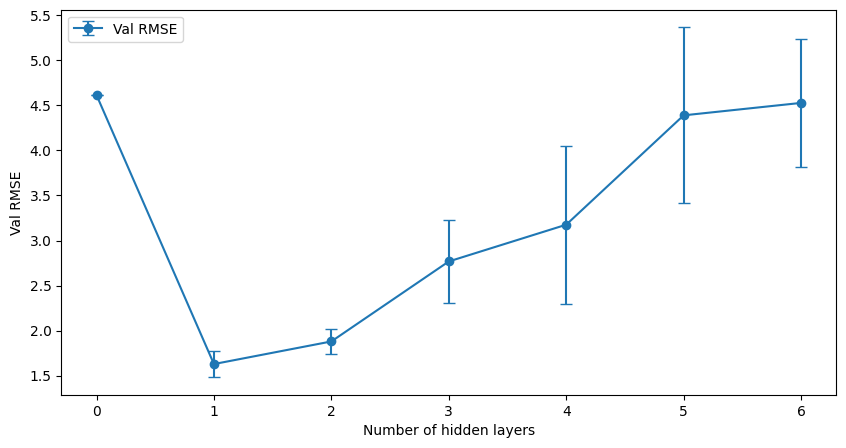

In [ ]:
plt.figure(figsize=(10, 5))
plt.errorbar(np.arange(len(rmses)), rmses, yerr=stds, marker='o', capsize=4, label='Val RMSE')
plt.xlabel('Number of hidden layers')
plt.ylabel('Val RMSE')
plt.legend()
plt.show()

Having zero hidden layers makes the model fully linear and it performs quite badly. One or two hidden layers seems to be optimal. When we add too many layers, the model degrades and performance becomes really bad. This is a common problem, training deep nets is hard. Anyways, this is not the scope of this assignment/course, so a shallow network with a single hidden layer will probably suffice.

Now that we have frozen the architecture to a single hidden layer, it might be tempting to ask how many neurons we should use. But this likely depends on the specific activation function: maybe a simple activation function like ReLU needs more neurons than e.g Sigmoid?

Lets try to optimize these two hyperparameters jointly. Holding everything else frozen.

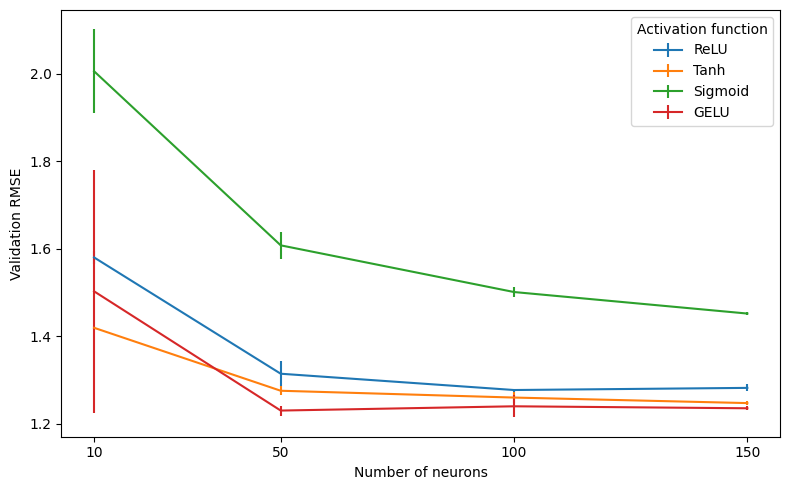

In [ ]:
num_neurons = [10, 50, 100, 150]
activation_functions = [nn.ReLU(), nn.Tanh(), nn.Sigmoid(), nn.GELU()]
repeats = 2

results = {}
for activation in activation_functions:
    layers = [[2, n, 1] for n in num_neurons]
    rmses, stds = sweep(layers, repeats, activation, 0.01, 5000, patience=10)
    results[type(activation).__name__] = (rmses, stds)

plt.figure(figsize=(8, 5))
for name, (rmses, stds) in results.items():
    plt.errorbar(num_neurons, rmses, yerr=stds, label=name)

plt.xlabel('Number of neurons')
plt.ylabel('Validation RMSE')
plt.xticks(num_neurons)
plt.legend(title='Activation function')
plt.tight_layout()
plt.show()

Jointly searching for hyperparameters gets expensive really fast. One could train a bit faster by using a GPU, but the exponential combinations of hyperparameters will quickly catch up. This is why our general approach so far has been to choose one variable at a time, freeze everything else, and find a good value/range for that one variable. After that, we move on to a new variable. This is often referred to as greedy search. 

From the plot it seems like too few neurons makes the model underfit. Increasing the number of neurons has diminishing return after ~100.

We also see that there is a noticeable difference in how well the activation functions perform overall. In theory, if you have a big enough network it should be able to fit any function. But in practice, the activation functions can make a huge difference. It's typically very difficult to justify why exactly one works better than others. There are reasons though, but this is not relevant for the assignment.

Let's go with 100 GeLU neurons and see how we are doing on the test set: 

Epoch 0, train loss: 21.288387298583984, val loss: 22.33945655822754
Epoch 500, train loss: 3.445127010345459, val loss: 3.4192745685577393
Epoch 1000, train loss: 1.6626663208007812, val loss: 1.894163727760315
Epoch 1500, train loss: 1.2833890914916992, val loss: 1.6288198232650757
Epoch 1758, train loss: 1.2059588432312012, val loss: 1.5911991596221924
Train RMSE: 1.0991325903163736, Val RMSE: 1.261816770920953


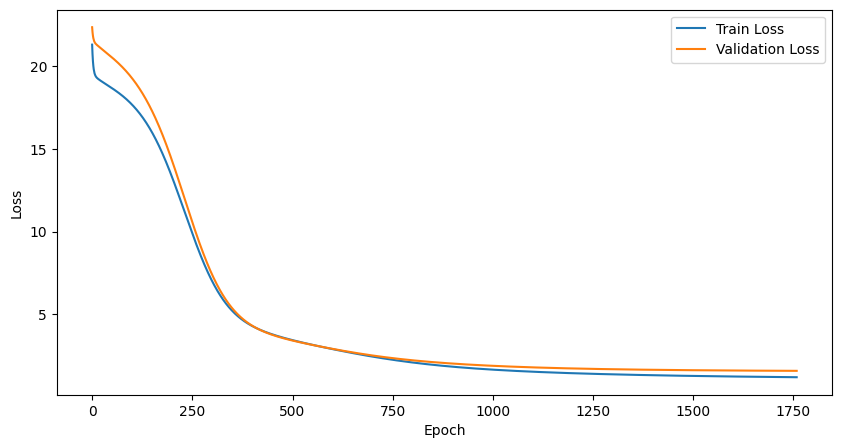

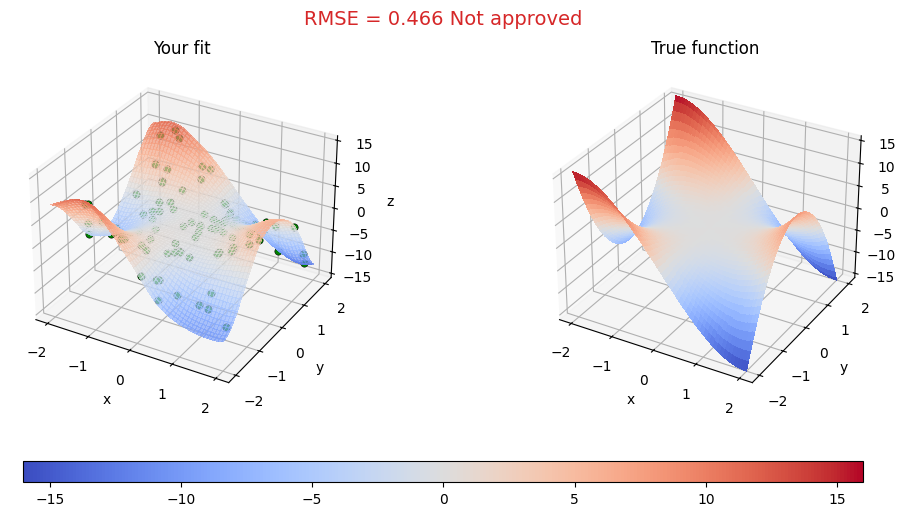

In [ ]:
model, _, _ = run_experiment(neurons_per_layer=[2, 100, 1], activation_function=nn.GELU(), learning_rate=0.01, num_epochs=5000, patience=10, verbose=True, plot_losses=True)
plot_complex_fit(test_features, model(X_test).detach().numpy())
plt.show()

Taking a step back (slightly cheating by peeking at the test performance), we can see that we are getting somewhat close. Visually, it does not look like we are overfitting, there are no sharp bends or anything that would indicate noise fitting. This likely means that we either have a too simplistic model, or that our optimizer is not finding ideal solutions.

Lets try to add momentum to our SGD optimizer. The idea behind momentum is quite intuitive: Imagine that a weight is really far away from its optimal value. Maybe its 0, but it should be 2. Then imagine that SGD does a tiny update to it, say 0.01 for every iteration. It would take 200 iterations before the weight reaches its target value. What momentum does is that it saves previous updates to each weight, and if there is a clear trend in where a weight is approaching, then it takes larger steps. In the hill analogy, it's similar to a ball rolling down a hill, compared to a person taking constant steps.

Epoch 0, train loss: 22.680130004882812, val loss: 22.80561637878418
Epoch 500, train loss: 1.0694472789764404, val loss: 1.4806616306304932
Epoch 797, train loss: 0.9921401143074036, val loss: 1.4449158906936646
Train RMSE: 0.9967517549390726, Val RMSE: 1.202454367662037


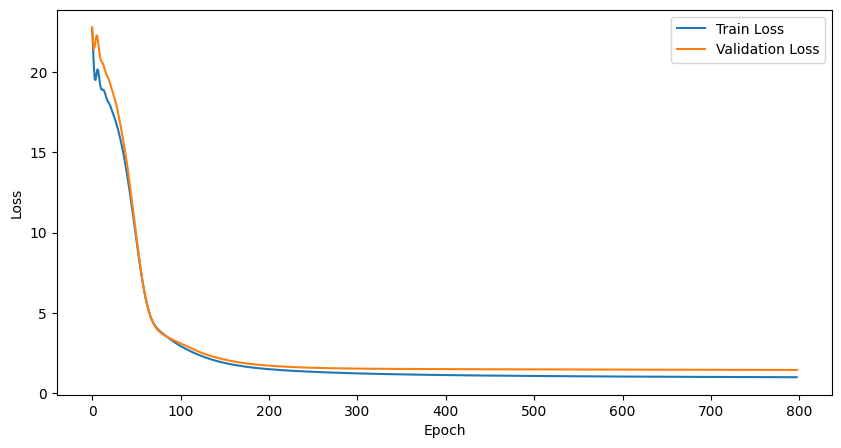

In [ ]:
_ = run_experiment(neurons_per_layer=[2, 100, 1], activation_function=nn.GELU(), learning_rate=0.01, num_epochs=5000, patience=10, verbose=True, plot_losses=True, momentum=0.85)

Nice! Momentum makes the model converge a lot faster. Our local/global minima did not change much though. Instead of using SGD with momentum, lets try Adam. This is by far the most popular optimizer in deep learning. In addition to using momentum, it also uses "adaptive learning rates" for each parameter. The theory behind Adam is quite dense, just know that it is a variant of gradient descent.

Epoch 0, train loss: 22.630603790283203, val loss: 22.860776901245117
Epoch 270, train loss: 1.001255989074707, val loss: 1.4458764791488647
Train RMSE: 1.0054905483725425, Val RMSE: 1.2024665120432456


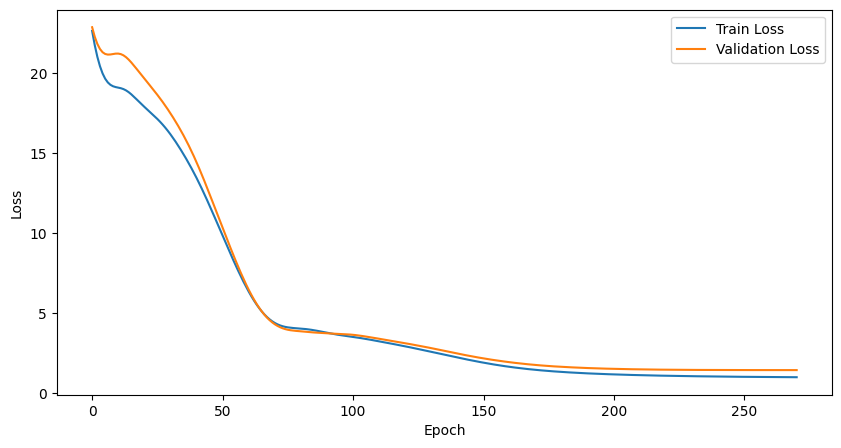

In [ ]:
_ = run_experiment(neurons_per_layer=[2, 100, 1], activation_function=nn.GELU(), learning_rate=0.01, num_epochs=5000, patience=10, verbose=True, plot_losses=True, optimizer=optim.Adam)

Not a huge difference, we do converge a bit faster, but the validation loss is still very similar. Let's keep it. Now that we have changed a few things, maybe we can handle multiple layers better now? Lets redo the layer sweep from earlier. 

The changes from before are: 
- 10->100 neurons
- relu -> gelu
- sgd -> adam.

In [ ]:
h = 100 # number of neurons in each hidden layer
layers = [[2, 1], [2, h, 1], [2, h, h, 1], [2, h, h, h, 1], [2, h, h, h, h, 1], [2, h, h, h, h, h, 1], [2, h, h, h, h, h, h, 1]]
rmses, stds = sweep(layers, 5, nn.GELU(), 0.01, 5000, patience=10, optimizer=optim.Adam)

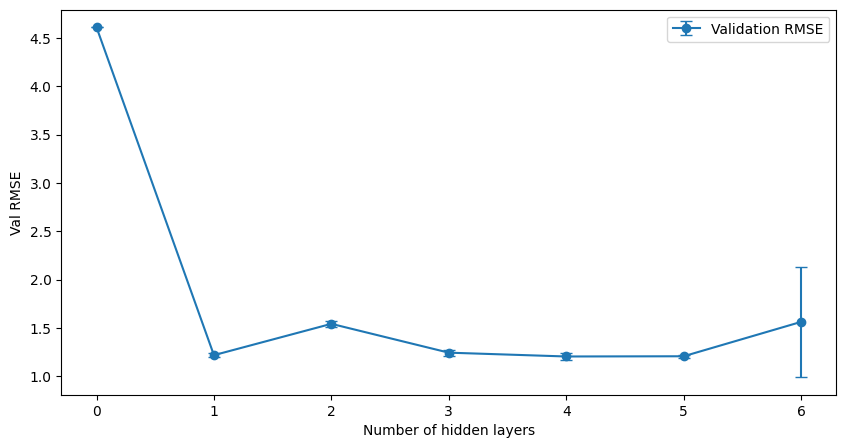

In [ ]:
plt.figure(figsize=(10, 5))
plt.errorbar(np.arange(len(rmses)), rmses, yerr=stds, marker='o', capsize=4, label='Validation RMSE')
plt.xlabel('Number of hidden layers')
plt.ylabel('Val RMSE')
plt.legend()
plt.show()

Deeper networks no longer degrades like before, that's cool! However, there isn't really any advantage of using a deeper network in our simple regression problem. Let's stick with a single hidden layer.

Maybe the architecture is as good as it gets, lets try to see if there any aspects about the data we can improve. A common practice is to standardize inputs and outputs. Let's try standardizing input features first

In [ ]:
class GELUMLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc1 = nn.Linear(2, 100)
        self.fc2 = nn.Linear(100, 1)
        self.gelu = nn.GELU()

    def forward(self, x):
        return self.fc2(self.gelu(self.fc1(x)))

model = GELUMLP()

optimizer = optim.Adam(model.parameters(), lr=0.01)
criterion = nn.MSELoss()

train_features_standardized = (X_train - X_train.mean(dim=0)) / X_train.std(dim=0)
test_features_standardized = (X_test - X_train.mean(dim=0)) / X_train.std(dim=0)

for epoch in range(1000): # no early stopping here, woopsie
    optimizer.zero_grad()
    outputs = model(train_features_standardized)
    loss = criterion(outputs, y_train)
    loss.backward()

    optimizer.step()

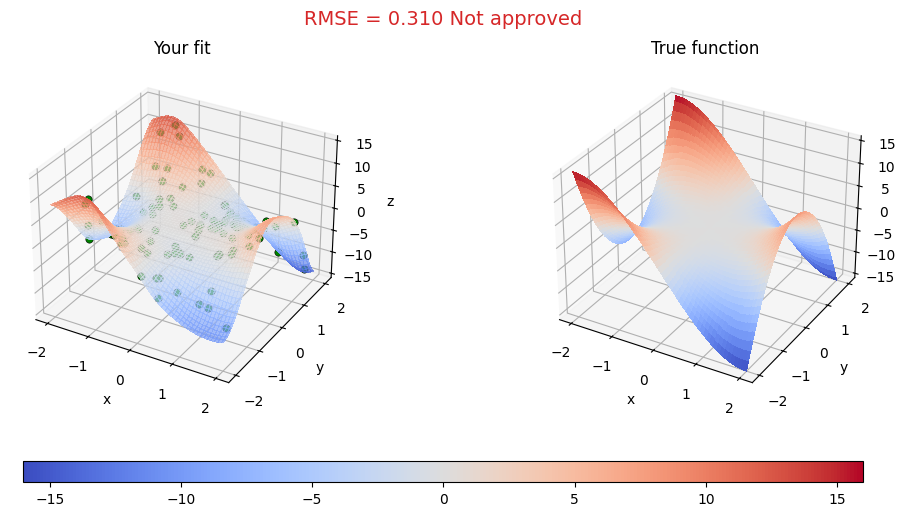

In [ ]:
with torch.no_grad():
    preds = model(test_features_standardized).numpy()

plot_complex_fit(test_features, preds)
plt.show()

Input standardization does not matter too much. Since the input features were already [-2,2] this change wasn't that big. Next, lets try standardizing the target aswell. The idea here is that the optimizer does not need to use many iterations just to get the target to the right scale, instead, it can focus on learning patterns immediately.

In [ ]:
model = GELUMLP()

optimizer = optim.Adam(model.parameters(), lr=0.01)
criterion = nn.MSELoss()

train_y_standardized = (y_train - y_train.mean()) / y_train.std()

for epoch in range(1000):
    optimizer.zero_grad()
    outputs = model(train_features_standardized)
    loss = criterion(outputs, train_y_standardized)
    loss.backward()

    optimizer.step()

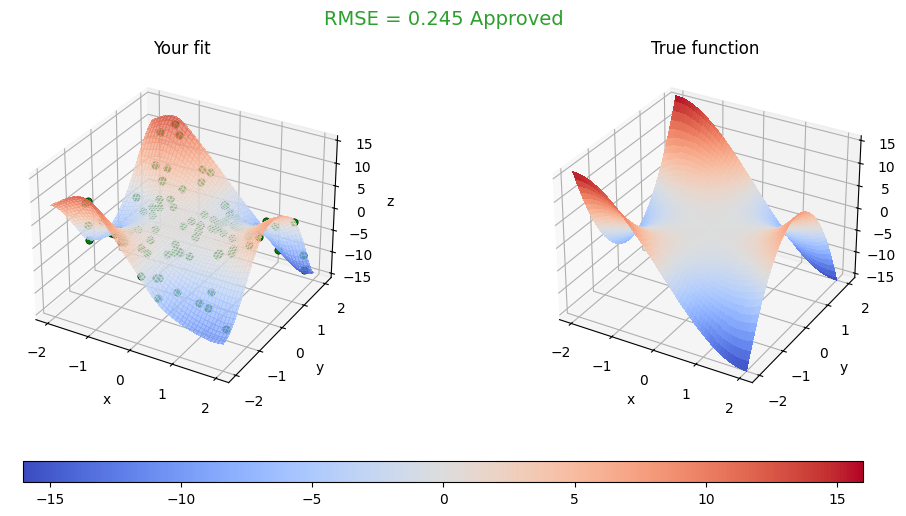

In [ ]:
with torch.no_grad():
    preds = model(test_features_standardized).numpy()
# Remember to scale the predictions back to the original scale!
preds = preds * y_train.std().item() + y_train.mean().item()

plot_complex_fit(test_features, preds)
plt.show()

Nice! just below the threshold!